# 12 - Core Calibration and the Digital Core

**Part B - Petrophys Curriculum**

Wireline logs are *indirect* measurements. A neutron tool counts hydrogen, a
density tool counts back-scattered gamma rays - neither one *is* porosity. The
ground truth against which every log interpretation is ultimately judged is the
**core**: a physical cylinder of rock brought to surface and measured in the
laboratory.

This lesson has two halves:

1. **Core-to-log calibration** - tie laboratory helium porosity and Klinkenberg
   permeability to the logs, quantify the mismatch ($R^2$, bias, RMSE), and fit a
   **poro-perm transform** so we can predict permeability everywhere the core did
   not sample.
2. **Rock typing on the cored interval** - cluster real wireline logs into
   **electrofacies** with weighted K-means (`DigitalCoreFacies`), fingerprint
   each cluster with per-facies statistics, and read the clusters on a
   density-neutron cross-plot.

Everything in this lesson runs on the real cored well **30/6-5** (Oseberg,
North Sea). The library also ships digital-core readers for scanner data
(`XRFData`, `GrainSizeData`, `CoreMechanical`); 30/6-5 has no scanner
measurements, so those tools are referenced but not demonstrated - we do not
plot data that was never measured.

## Learning goals

By the end of this lesson you will be able to:

- Build a `CoreData` container directly from a cored well with
  `core_data_from_well` (from `petrophys.interpretation.core_analysis`).
- Calibrate a log-derived porosity against core with `calibrate_porosity`, and
  read the calibration statistics off a `CalibrationResult`.
- Fit a linear porosity correction (`fit_porosity_correction`) and a poro-perm
  transform (`fit_poro_perm_transform`), apply the transform to the log, and
  judge where the prediction is supported by core and where it extrapolates.
- Cluster wireline logs over the cored interval into electrofacies with
  `DigitalCoreFacies` / `FaciesResult`, and produce a per-facies statistics
  table.

## Why this matters

Every deterministic petrophysical answer - porosity, saturation, net pay,
volumes - inherits the systematic error of the logs it was built from. Core
calibration is how we *anchor* those logs to reality:

- **Porosity** measured by a density tool depends on an assumed matrix density.
  Get the grain density wrong and every porosity is biased. Core helium porosity
  fixes the tie point.
- **Permeability** is never measured by wireline; it is *always* a correlation.
  A poro-perm transform fitted to core plugs is the standard way to propagate a
  handful of lab measurements to the full log.

The **digital core** pushes this further. Instead of one plug every ~30 cm,
modern core scanners deliver *continuous* millimetre-to-centimetre logs of grain
size, elemental chemistry, strength, and colour. Clustering these into facies
gives a rock-typing scheme that is fully data-driven and reproducible - the
kind of product commercial core-scanning services deliver.

> **Units convention.** In `petrophys`, porosity and saturation are stored as
> **fractions (v/v, 0-1)**, permeability in **mD**, and grain/bulk density in
> **g/cm3**.

### Prerequisites

Assumes the Part A porosity and permeability lessons (04, 08). Part 2 uses
`DigitalCoreFacies`, which needs **scikit-learn** for K-means clustering.
Install it with the machine-learning extra (Python 3.11 or later):

```bash
pip install "petrophys[ml]"
```

Part 1 (core-to-log calibration) runs with the base installation.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import petrophys as pp

print("petrophys", pp.__version__)
print("geolink wells:", pp.list_samples("geolink"))

petrophys 3.0.0
geolink wells: ['15_9-14', '16_7-1', '25_5-1', '30_6-5']


---
## Part 1 - Core-to-log calibration

### 1.1 Loading core measurements from the well

Well **30/6-5** is unusual and convenient: it ships with the laboratory core
measurements already merged into the LAS file as dedicated curves -
`PHIC` (core helium porosity), `KH_CORE` (horizontal Klinkenberg permeability),
`GDEN` (grain density), and `SWC` / `SOC` (Dean-Stark saturations).

`core_data_from_well` sweeps the well for these mnemonics and packs the samples
that actually carry a lab measurement into a `CoreData` object.

In [2]:
well = pp.read(pp.sample("30_6-5"))

# Sanitize the field name for ASCII printing (this header has mojibake).
field_ascii = (well.header.field or "Unknown").encode("ascii", "replace").decode("ascii")
print("Well :", well.name, "| field:", field_ascii)
print("Depth: %.1f - %.1f %s" % (well.start_depth, well.stop_depth, well.depth_unit))
print("Curves present:", ", ".join(well.curves))

Well : 30/6-5 | field: OSEBERG ?ST
Depth: 176.6 - 3556.1 m
Curves present: LITHOLOGY_GEOLINK, CALI, DRHO, NPHI, RHOB, PEF, GR, DTC, DTE, RDEP, SP, RSHA, RMED, BS, PHIC, GDEN, KH_CORE, KV_CORE, SWC, SOC


In [3]:
from petrophys.interpretation.core_analysis import core_data_from_well

core = core_data_from_well(well)
print(core)
print()
print('Plugs                :', core.n_plugs)
print('Cored interval       : %.1f - %.1f %s' % (core.top, core.bottom, well.depth_unit))
print('Porosity source curve:', core.metadata.get('core_porosity_curve'))
print('Perm source curve    :', core.metadata.get('core_permeability_curve'))
print('GD source curve      :', core.metadata.get('core_grain_density_curve'))
print()
print('Valid porosity plugs :', int(np.isfinite(core.porosity).sum()))
print('Valid perm plugs     :', int(np.isfinite(core.permeability).sum()))
print('Core porosity range  : %.3f - %.3f v/v' % (np.nanmin(core.porosity), np.nanmax(core.porosity)))
print('Core perm range      : %.2f - %.1f mD' % (np.nanmin(core.permeability), np.nanmax(core.permeability)))

CoreData(plugs=201, depth=2800.5-2947.9, props=[porosity, perm, GD, Sw])

Plugs                : 201
Cored interval       : 2800.5 - 2947.9 m
Porosity source curve: PHIC
Perm source curve    : KH_CORE
GD source curve      : GDEN

Valid porosity plugs : 200
Valid perm plugs     : 198
Core porosity range  : 0.022 - 0.277 v/v
Core perm range      : 0.02 - 5826.0 mD


### 1.2 Calibrating an *independent* log porosity

To calibrate honestly we must compare core against a log porosity that was
computed **independently** of the core. (Comparing `PHIC` against itself would
trivially give $R^2 = 1$.) So we compute a fresh **density porosity** from the
bulk-density curve using the textbook relation

$$\phi_D = \frac{\rho_{ma} - \rho_b}{\rho_{ma} - \rho_f}$$

with an *assumed* sandstone matrix density $\rho_{ma} = 2.65$ g/cm3 and fluid
density $\rho_f = 1.0$ g/cm3. The whole point of calibration is to discover how
wrong those assumptions are.

In [4]:
RHO_MA = 2.65   # assumed quartz matrix density (g/cm3)
RHO_F  = 1.00   # assumed fluid density (g/cm3)

rhob = np.asarray(well.get('RHOB').data, dtype=float)
phid = np.clip((RHO_MA - rhob) / (RHO_MA - RHO_F), 0.0, 0.5)
well.add_curve('PHID', phid, 'v/v', 'Density porosity (rho_ma=2.65)')

print('PHID added. Mean density porosity: %.3f v/v' % np.nanmean(phid))

PHID added. Mean density porosity: 0.286 v/v


In [5]:
from petrophys.interpretation.core_analysis import calibrate_porosity

cal = calibrate_porosity(well, core, log_curve='PHID')
print('Core vs log density-porosity calibration')
print('  n points  :', cal.n_points)
print('  R^2       : %.3f' % cal.r_squared)
print('  Bias (log-core): %+.4f v/v' % cal.bias)
print('  RMSE      : %.4f v/v' % cal.rmse)
print('  Linear fit: log = %.3f * core + %.4f' % (cal.slope, cal.intercept))

Core vs log density-porosity calibration
  n points  : 200
  R^2       : 0.645
  Bias (log-core): -0.0198 v/v
  RMSE      : 0.0461 v/v
  Linear fit: log = 0.860 * core + 0.0045


A **positive bias** means the log reads systematically *higher* than core; a
negative bias means it reads low. Read the sign and size of the bias printed
above: on 30/6-5 the density porosity runs **low** relative to core, and the
scatter ($R^2$ well below 1) reflects the assumed matrix density not being
exactly right for every plug - exactly the kind of systematic error
calibration exists to expose.

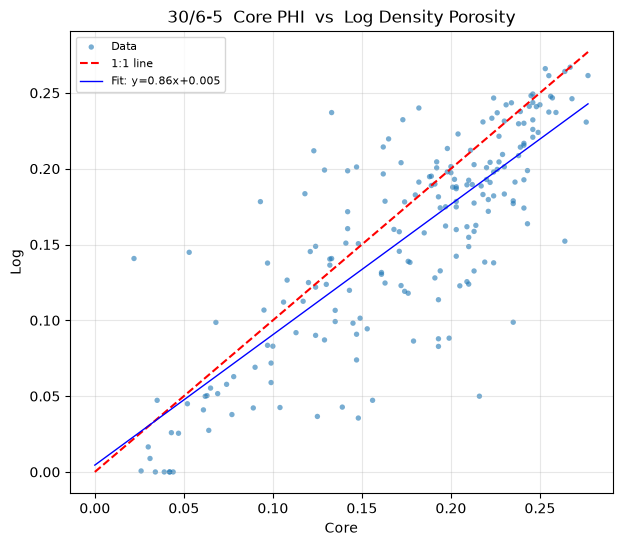

In [6]:
from petrophys.visualization.core import plot_calibration

fig, ax = plot_calibration(cal, title='30/6-5  Core PHI  vs  Log Density Porosity')
plt.show()

### 1.3 A porosity correction

`fit_porosity_correction` fits $\phi_{core} = A\,\phi_{log} + B$ so we can map
the *full* log porosity onto its core-equivalent value. This is the transfer
function you would apply downstream before computing volumes.

In [7]:
from petrophys.interpretation.core_analysis import fit_porosity_correction

corr = fit_porosity_correction(well, core, log_curve='PHID')
print(corr)
print()
# Apply to two example log readings
for phi_log in (0.10, 0.25):
    print('  log phi %.2f -> core-equivalent %.3f' % (phi_log, float(corr.predict(phi_log))))

PorosityCorrection(PHIcore = 0.717*PHID + 0.065, R^2=0.580, RMSE=0.0383, n=193)

  log phi 0.10 -> core-equivalent 0.136
  log phi 0.25 -> core-equivalent 0.244


### 1.4 Fitting a poro-perm transform

Permeability spans orders of magnitude, so the industry-standard transform is
linear in **log10** space:

$$\log_{10}(k) = A\,\phi + B \quad\Longleftrightarrow\quad k = 10^{B}\,10^{A\phi}$$

`fit_poro_perm_transform` fits this straight from the `CoreData` porosity and
permeability arrays.

In [8]:
from petrophys.interpretation.core_analysis import fit_poro_perm_transform

transform = fit_poro_perm_transform(core)
print('Poro-perm transform (log10 K = A*phi + B)')
print('  A (slope)    : %.2f' % transform.A)
print('  B (intercept): %.2f' % transform.B)
print('  R^2          : %.3f' % transform.r_squared)
print('  n plugs      :', transform.n_points)
print()
for phi in (0.10, 0.20, 0.30):
    print('  phi %.2f -> k = %.2f mD' % (phi, float(transform.predict(phi))))

Poro-perm transform (log10 K = A*phi + B)
  A (slope)    : 21.72
  B (intercept): -2.54
  R^2          : 0.777
  n plugs      : 198

  phi 0.10 -> k = 0.43 mD
  phi 0.20 -> k = 64.23 mD
  phi 0.30 -> k = 9540.29 mD


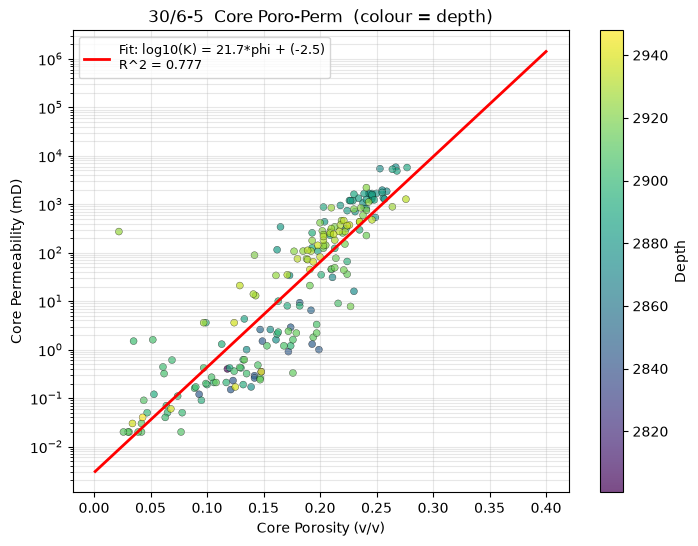

In [9]:
from petrophys.visualization.core import plot_poro_perm

fig, ax = plot_poro_perm(core, transform=transform,
                         title='30/6-5  Core Poro-Perm  (colour = depth)')
plt.show()

### 1.5 Applying the transform back onto the log

`apply_poro_perm_transform` writes a continuous predicted-permeability curve onto
the well using a chosen porosity input. We feed it our density porosity, so the
curve covers the *entire* logged interval, not just the cored plugs. We store
it as `PERM_CORE`, a name the core-overlay plotter recognises, so the next
figure can overlay the measured plugs on the prediction.

A transform is only supported where the plugs are: the cored interval (here
inside the Brent reservoir) and the porosity range the plugs span. Outside
that, it **extrapolates**. In the shallow, poorly compacted section the density
porosity is very high, the exponential transform explodes, and the function
clips the result at its 100,000 mD ceiling. So we summarise the prediction
over the cored interval only, and count how many samples elsewhere hit the
ceiling.

In [10]:
from petrophys.interpretation.core_analysis import apply_poro_perm_transform

perm_pred = apply_poro_perm_transform(well, transform,
                                      porosity_curve="PHID",
                                      output_curve="PERM_CORE")
print("Predicted permeability curve PERM_CORE added to well.")

depth = np.asarray(well.depth, dtype=float)
cored = (depth >= core.top) & (depth <= core.bottom) & np.isfinite(perm_pred)
k_cored = perm_pred[cored]
print()
print("Cored interval %.1f-%.1f m (%d log samples):" % (core.top, core.bottom, k_cored.size))
print("  log-predicted k: median %.2f mD, P10 / P90 %.3f / %.1f mD"
      % (np.median(k_cored), np.percentile(k_cored, 10), np.percentile(k_cored, 90)))
print("  core plugs     : median %.2f mD, P10 / P90 %.3f / %.1f mD"
      % (np.nanmedian(core.permeability), np.nanpercentile(core.permeability, 10),
         np.nanpercentile(core.permeability, 90)))

finite = np.isfinite(perm_pred)
at_ceiling = finite & (perm_pred >= 1e5)
print()
print("Whole logged well: %d of %d samples sit at the 100,000 mD ceiling (extrapolated)"
      % (at_ceiling.sum(), finite.sum()))

Predicted permeability curve PERM_CORE added to well.

Cored interval 2800.5-2947.9 m (968 log samples):
  log-predicted k: median 3.01 mD, P10 / P90 0.015 / 520.1 mD
  core plugs     : median 44.50 mD, P10 / P90 0.141 / 1285.0 mD

Whole logged well: 10881 of 22171 samples sit at the 100,000 mD ceiling (extrapolated)


Compare the two medians over the cored interval. The log prediction samples
**every** depth, including the shaly beds between the sands, whereas plugs tend
to be cut from the better rock; and the density porosity reads low (the bias in
section 1.2), which the exponential transform amplifies. Feeding the transform
a core-corrected porosity (Exercise 3) is the natural next step. The ceiling
count shows why a whole-well median of this curve would be meaningless.

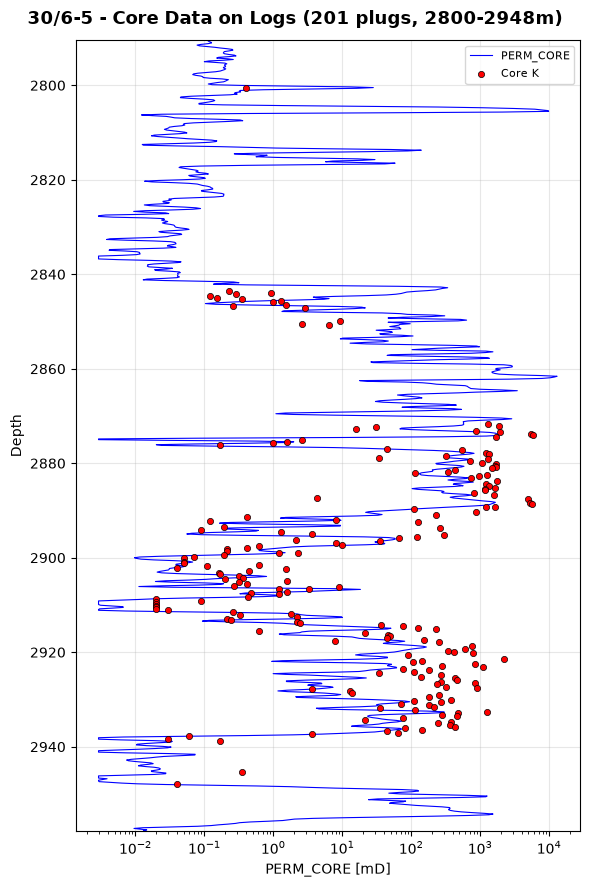

In [11]:
# Overlay: continuous predicted perm vs the discrete core plugs, over the cored
# interval. PERM_CORE is a curve name plot_core_on_logs recognises, so the core
# permeability plugs are overlaid automatically as markers on the log-scale track.
from petrophys.visualization.core import plot_core_on_logs

fig, axes = plot_core_on_logs(
    well, core,
    curves=["PERM_CORE"],
    depth_range=(core.top - 10, core.bottom + 10),
    figsize=(6, 9),
)
plt.show()

---
## Part 2 - Rock typing with the digital-core toolkit

Plug-based core analysis samples one point every ~30 cm. Modern **core scanning**
delivers *continuous* high-resolution logs: laser grain size, XRF elemental
chemistry, scratch-test strength, ultrasonic velocities, and RGB colour. The
`petrophys.interpretation.core_analysis` digital-core suite ingests these and turns them into
interpretation-ready products: `XRFData` (mineral proxies, elemental ratios),
`GrainSizeData` (Wentworth classes, sorting, Kozeny-Carman permeability), and
`CoreMechanical` (dynamic elastic moduli from Vp/Vs).

> **Data note.** 30/6-5 carries no scanner data, so those three tools are not
> demonstrated here: a synthetic demo log is a figure waiting to be mistaken
> for a measurement. What the well *does* support is the clustering member of
> the suite, `DigitalCoreFacies`, applied to real wireline logs over the cored
> interval - a standard electrofacies workflow.

### 2.1 Facies classification with weighted K-means

`DigitalCoreFacies` standardises each input feature, applies an optional
`sqrt(weight)` emphasis, and runs K-means. The result is a `FaciesResult`
carrying the per-sample labels, cluster centroids (back in original units), and
convenience methods `proportions()` and `statistics()`.

Here we use **real 30/6-5 wireline logs** (GR, RHOB, NPHI, PEF) over the cored
interval as the multi-parameter feature set - a legitimate electrofacies
exercise - to keep the demonstration grounded in real data.

In [12]:
from petrophys.interpretation.core_analysis import DigitalCoreFacies

# Real logs over the cored interval as clustering features.
top, bottom = core.top, core.bottom
dep = np.asarray(well.depth, dtype=float)
m = (dep >= top) & (dep <= bottom)

features = {
    'GR':   np.asarray(well.get('GR').data,   dtype=float)[m],
    'RHOB': np.asarray(well.get('RHOB').data, dtype=float)[m],
    'NPHI': np.asarray(well.get('NPHI').data, dtype=float)[m],
    'PEF':  np.asarray(well.get('PEF').data,  dtype=float)[m],
}
depth_m = dep[m]
print('Samples in interval:', depth_m.size)
print('Finite per feature :', {k: int(np.isfinite(v).sum()) for k, v in features.items()})

Samples in interval: 968
Finite per feature : {'GR': 968, 'RHOB': 968, 'NPHI': 968, 'PEF': 968}


In [13]:
clf = DigitalCoreFacies(n_facies=4, n_init=10, random_state=42)
result = clf.fit(depth_m, features, weights={'GR': 2.0})   # emphasise GR (shaliness)

print('Facies model fitted.')
print('  n_facies :', result.n_facies)
print('  inertia  : %.1f' % result.inertia)
print('  labels   :', np.unique(result.facies[result.facies > 0]))
print()
print('Facies proportions:')
for fc, frac in result.proportions().items():
    print('  facies %d : %5.1f %%' % (fc, 100 * frac))

Facies model fitted.
  n_facies : 4
  inertia  : 1264.9
  labels   : [1 2 3 4]

Facies proportions:
  facies 1 :  38.1 %
  facies 2 :  48.0 %
  facies 3 :   4.5 %
  facies 4 :   9.3 %


#### Per-facies statistics table

`statistics()` returns the P13 / P50 / P87 of every feature within each facies -
the fingerprint that lets you *name* the clusters (clean sand, shale,
calcite-cemented streak, etc.).

In [14]:
stats = result.statistics(features)
# Show the median (P50) of each feature per facies for a compact fingerprint.
p50_cols = [c for c in stats.columns if c.endswith("_P50")]
summary = stats[["count", "proportion_pct"] + p50_cols].round(2)
summary.columns = ["count", "prop_%"] + [c.replace("_P50", "_median") for c in p50_cols]

# Cluster numbers are arbitrary labels: identify clusters by their fingerprint.
print("Cleanest facies (lowest median GR)  :", summary["GR_median"].idxmin())
print("Shaliest facies (highest median GR) :", summary["GR_median"].idxmax())
summary

Cleanest facies (lowest median GR)  : 2
Shaliest facies (highest median GR) : 1


,count,prop_%,GR_median,RHOB_median,NPHI_median,PEF_median
facies,,,,,,
1,369,38.12,97.31,2.57,0.29,3.92
2,465,48.04,39.09,2.34,0.21,4.36
3,44,4.55,88.81,2.24,0.41,9.62
4,90,9.30,94.91,2.32,0.37,5.43


#### Facies on a cross-plot

A density-neutron cross-plot coloured by facies shows how the clusters
separate in petrophysical space. One display detail matters: **a facies label
is a category, not a number**. A continuous colorbar is the wrong tool - it
invents in-between colours and ticks (facies 2.5 does not exist) and leaves
the reader guessing which colour maps to which cluster. So we scatter each
facies as its own series with a discrete colour, and put the cluster
fingerprint (sample count and median GR) straight into the legend.

Read it against the statistics table above. K-means cluster numbers are
arbitrary (they can change with the library version or random seed), so name
each cluster by its fingerprint:

- The **lowest-GR facies** sits at low NPHI and low RHOB: the clean, porous
  reservoir sand.
- A **high-GR facies at higher RHOB** is shale. The neutron reads high because
  clay-bound hydrogen counts as apparent porosity.
- Smaller high-GR clusters pushed to **very high NPHI and low RHOB**, or with an
  unusually high PEF, are shale streaks with anomalous log response - bad hole
  or heavy minerals rather than a clean mineralogy signal. Clusters inherit
  whatever artefacts the input logs carry.

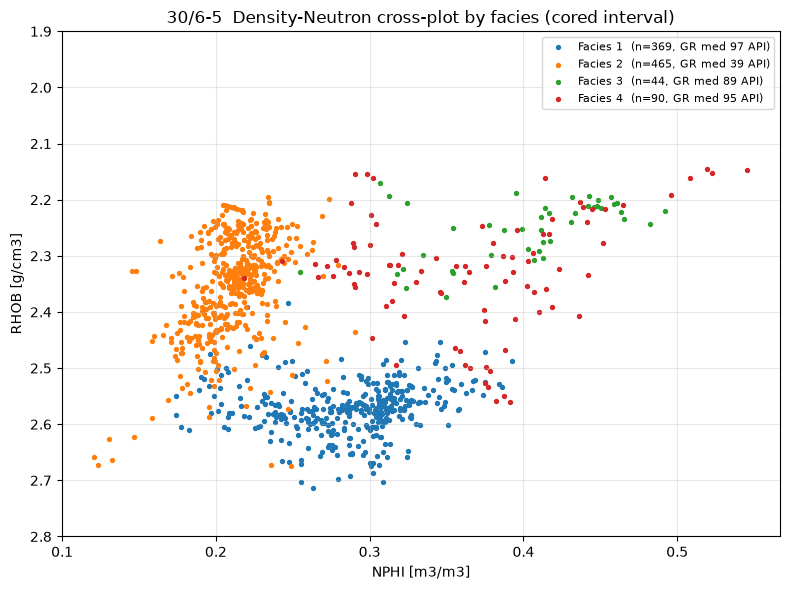

In [15]:
# FACIES is a category, so no colorbar: one scatter series per facies with a
# discrete colour, and the fingerprint (n, median GR) carried in the legend.
nphi_s, rhob_s, gr_s = features['NPHI'], features['RHOB'], features['GR']

fig, ax = plt.subplots(figsize=(8, 6))
palette = plt.get_cmap('tab10').colors
for k, fc in enumerate(np.unique(result.facies[result.facies > 0])):
    sel = result.facies == fc
    ax.scatter(nphi_s[sel], rhob_s[sel], s=8, color=palette[k],
               label='Facies %d  (n=%d, GR med %.0f API)'
                     % (fc, sel.sum(), np.nanmedian(gr_s[sel])))
ax.set_xlabel('NPHI [m3/m3]')
ax.set_ylabel('RHOB [g/cm3]')
ax.set_ylim(2.8, 1.9)   # density increases downward
ax.grid(alpha=0.3)
ax.legend(loc='upper right', fontsize=8)
ax.set_title('30/6-5  Density-Neutron cross-plot by facies (cored interval)')
plt.tight_layout()
plt.show()

## Pitfalls and parameter choices

- **Calibrate against an *independent* log.** Comparing a curve against itself
  gives a meaningless $R^2 = 1$. We built density porosity from RHOB specifically
  so the comparison against core `PHIC` is real.
- **Depth-matching.** Core depth and log depth are rarely on the same datum; a
  small shift can destroy an otherwise good correlation. `calibrate_porosity`
  interpolates the log to the core depths - always sanity-check the tie.
- **Poro-perm is log-linear.** Never fit permeability in linear space; a few
  high-perm plugs will dominate the least-squares fit. `fit_poro_perm_transform`
  works in $\log_{10}$ for exactly this reason.
- **A transform is valid where the core is.** Applied outside the cored rock
  types and porosity range it extrapolates, often to the clip limits. Report
  predicted permeability for the calibrated interval, not the whole well.
- **K-means needs scaling and sensible K.** `DigitalCoreFacies` standardises
  features for you, but *you* choose `n_facies` and the weights. Too many facies
  over-fits noise; too few merges distinct rock types.

## Recap

- `core_data_from_well` pulled the real core plugs of 30/6-5 into a `CoreData`.
- Density porosity calibrated against core exposes a bias and scatter that
  trace back to the assumed matrix density.
- A $\log_{10}(k)=A\phi+B$ transform propagated the core-perm plugs to a
  continuous predicted-permeability curve - trustworthy over the cored
  interval, extrapolated (and clipped) elsewhere.
- `DigitalCoreFacies` clustered real wireline logs into facies with a per-facies
  statistics fingerprint and a readable density-neutron cross-plot.

## Try it yourself

> **Exercise 1.** Re-run the porosity calibration using a *neutron* porosity
> (`well.get('NPHI')`) instead of density porosity. Which log ties the core
> better, and what does the bias tell you about gas or clay effects?
>
> **Exercise 2.** Change `n_facies` in `DigitalCoreFacies` to 6 and add `PEF` to
> the weights. Does the inertia drop meaningfully, or are you just splitting
> noise? Inspect the new per-facies statistics table.
>
> **Exercise 3.** Feed the fitted `transform` a corrected porosity
> (via `corr.predict`) instead of raw `PHID`. How much does the predicted
> permeability profile shift?

## What's next

Continue with **13 - ML Curve Imputation**, where pretrained models (XGBoost,
random forest and KNN) fill gaps in an existing log curve - the
machine-learning counterpart to the physics-based calibration you just did.